# Chapitre 1 - Cours 1 : penser les systèmes de données, l'exemple des timelines de Twitter

Le chapitre 1 pose le vocabulaire de tout le livre : **fiabilité**, **scalabilité** et
**maintenabilité**. Pour rendre la scalabilité concrète, le livre décrit la charge de
Twitter et la façon dont l'entreprise construit les timelines (fils d'accueil) de ses
utilisateurs. Ce notebook couvre la section *Thinking About Data Systems* et la
sous-section *Describing Load* de la section *Scalability*.

**Plan.**

- Penser les systèmes de données : des briques assemblées en un système composite.
1. Le schéma relationnel et la requête de timeline, exécutés sur SQLite.
2. Les ordres de grandeur de la charge, et ce qu'ils coûtent.
3. Le fan-out à l'écriture : des timelines matérialisées.
4. La loi de puissance des abonnés et le problème des célébrités.
5. L'approche hybride et le choix d'un seuil.
6. Décrire la charge : paramètres, moyennes et cas extrêmes.

In [1]:
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import requirements as rq
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")      # 1234567 -> « 1 234 567 »

## Penser les systèmes de données (section *Thinking About Data Systems*)

On range traditionnellement les outils en catégories bien séparées : bases de données,
caches, index de recherche, files de messages. Le livre défend une autre lecture : ces
catégories se brouillent (Redis sert de base et de file, Kafka de file durable qui
ressemble à une base), et surtout une application réelle en **assemble plusieurs**. Le
code applicatif devient alors le chef d'orchestre d'un **système de données composite**,
dont il doit garantir la cohérence : quand le cache est-il invalidé ? l'index est-il à
jour ? que se passe-t-il si l'un des composants tombe ?

Le schéma ci-dessous dessine une telle architecture. Le développeur qui l'écrit est
devenu, qu'il le veuille ou non, un **concepteur de système de données** : l'API qu'il
expose cache les détails, mais c'est à lui de garantir les propriétés de l'ensemble.

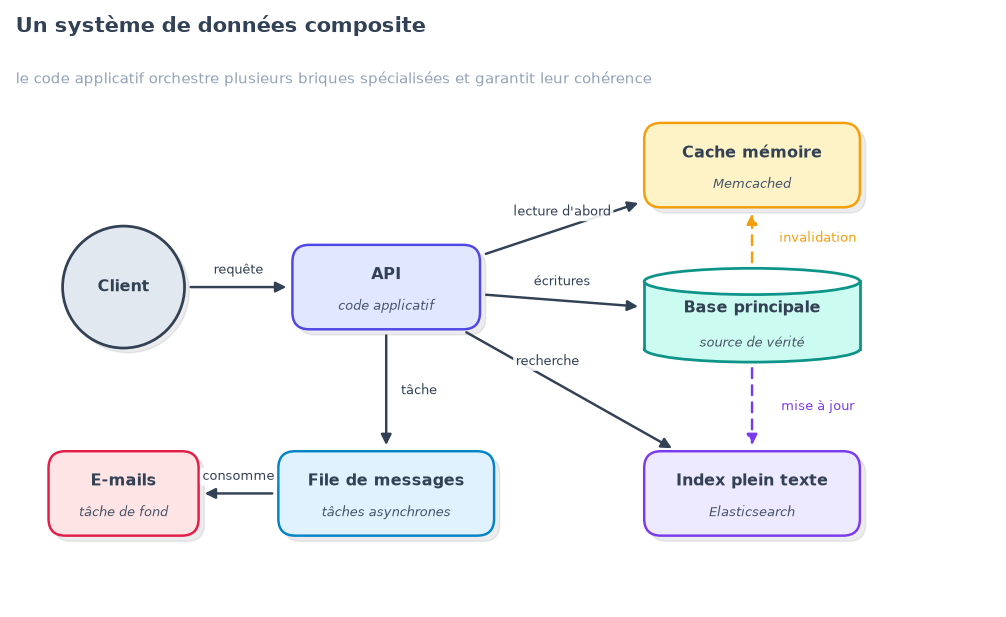

In [2]:
d = Diagram(10.5, 5.4, title="Un système de données composite",
            subtitle="le code applicatif orchestre plusieurs briques spécialisées et garantit leur cohérence")
d.box("client", 1.2, 3.4, "Client", kind="user", w=1.3, color=SLATE)
d.box("api", 4.0, 3.4, "API", sub="code applicatif", color=INDIGO, w=2.0)
d.box("cache", 7.9, 4.7, "Cache mémoire", sub="Memcached", color=AMBER, w=2.3)
d.box("db", 7.9, 3.1, "Base principale", sub="source de vérité", color=TEAL, kind="db", w=2.3, h=1.0)
d.box("idx", 7.9, 1.2, "Index plein texte", sub="Elasticsearch", color=VIOLET, w=2.3)
d.box("q", 4.0, 1.2, "File de messages", sub="tâches asynchrones", color=SKY, w=2.3)
d.box("mail", 1.2, 1.2, "E-mails", sub="tâche de fond", color=ROSE, w=1.6)
d.arrow("client", "api", "requête")
d.arrow("api", "cache", "lecture d'abord")
d.arrow("api", "db", "écritures", label_offset=(0, 0.2))
d.arrow("api", "idx", "recherche", label_pos=0.4)
d.arrow("db", "cache", "invalidation", style="dashed", color=AMBER, label_offset=(0.7, 0))
d.arrow("db", "idx", "mise à jour", style="dashed", color=VIOLET, label_offset=(0.7, 0))
d.arrow("api", "q", "tâche", label_offset=(0.35, 0))
d.arrow("q", "mail", "consomme")
d.show()

Les trois préoccupations qui structurent le chapitre se posent dès ce schéma :

- **fiabilité** : le système doit continuer à fonctionner correctement quand quelque
  chose se passe mal (panne d'un serveur, bogue, erreur humaine) ;
- **scalabilité** : quand la charge augmente (plus d'utilisateurs, plus de données), il
  doit exister des moyens raisonnables de suivre ;
- **maintenabilité** : au fil des années, de nombreuses personnes devront le faire
  tourner et le modifier, il faut que ce soit possible et productif.

> **À retenir.** Une application « gourmande en données » assemble des briques
> spécialisées (base, cache, index, file) ; celui qui les assemble conçoit un système
> de données et répond de sa fiabilité, de sa scalabilité et de sa maintenabilité.